# ClearCell - Integrated Group Preprocessing Pipeline
**Group:** 26-MTR-IT2011-04
**Module:** IT2011 - Artificial Intelligence and Machine Learning
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

This notebook integrates every member's individual preprocessing technique into a single, ordered, reproducible pipeline, producing the final processed dataset used for modelling in Step 3.

| Order | Technique | Owner |
|---|---|---|
| 1 | Missing data handling (median imputation) | IT25100170 - Thanthrige P.D.I. |
| 2 | Categorical (target) encoding | IT25101160 - Rukmalgoda R.D.D |
| 3 | Outlier detection & analysis | IT25101986 - Thashmina P. G. D. |
| 4 | Feature scaling | IT25102047 - Palihakkara P. J. |
| 5 | Feature selection (correlation analysis) | IT25102054 - Dinali L. D. G. N. |
| 6 | Dimensionality reduction (PCA, exploratory) | IT25102115 - Malka H. A. G. |

See **notebooks**/ for each member's detailed, standalone justification and visualization.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04')

In [ ]:
 print(os.getcwd())
 os.listdir('data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']
FEATURE_COLS = COLS[1:-1]

RAW_PATH = 'data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = 'results/eda_visualizations'
OUT_DIR = 'results/outputs'
LOG_DIR = 'results/logs'
for d in (VIZ_DIR, OUT_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Raw dataset loaded:", df.shape)
df.head()

Raw dataset loaded: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


## Step 1 - Handling Missing Data
*(IT25100170)* Convert the **'?'** marker in **Bare_Nuclei** to **NaN**, then impute with the median (robust to the feature's right-skew).

In [ ]:
df['Bare_Nuclei'] = df['Bare_Nuclei'].replace('?', np.nan).astype(float)
n_missing = df['Bare_Nuclei'].isna().sum()
median_bn = df['Bare_Nuclei'].median()
df['Bare_Nuclei'] = df['Bare_Nuclei'].fillna(median_bn)
print(f"Step 1 complete - imputed {n_missing} missing Bare_Nuclei values with median={median_bn}")
print("Remaining missing values in dataset:", df.isna().sum().sum())

Step 1 complete - imputed 16 missing Bare_Nuclei values with median=1.0
Remaining missing values in dataset: 0


## Step 2 - Encoding the Target Variable
*(IT25101160)* Map **Class**: 2 (benign) → 0, 4 (malignant) → 1.

In [ ]:
df['Class'] = df['Class'].map({2: 0, 4: 1})
print("Step 2 complete - Class encoded to binary 0/1")
print(df['Class'].value_counts().rename({0: 'Benign', 1: 'Malignant'}))

Step 2 complete - Class encoded to binary 0/1
Class
Benign       458
Malignant    241
Name: count, dtype: int64


## Step 3 - Outlier Analysis
*(IT25101986)* Flag statistical outliers via IQR, but - per the individual notebook's finding that 90.3% of flagged rows are malignant - **retain all rows**; extreme scores are real clinical signal, not data errors.

In [ ]:
for c in FEATURE_COLS:
    df[c] = df[c].astype(float)

any_outlier = pd.Series(False, index=df.index)
for c in FEATURE_COLS:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    any_outlier |= (df[c] < lb) | (df[c] > ub)

pct_malignant_flagged = (df.loc[any_outlier, 'Class'] == 1).mean() * 100
print(f"Step 3 complete - {any_outlier.sum()} rows flagged as statistical outliers "
      f"({pct_malignant_flagged:.1f}% malignant) - NO rows removed (signal, not error).")
print("Dataset shape unchanged:", df.shape)

Step 3 complete - 195 rows flagged as statistical outliers (90.3% malignant) - NO rows removed (signal, not error).
Dataset shape unchanged: (699, 11)


## Step 4 - Feature Scaling
*(IT25102115)* Standardize all 9 features (zero mean, unit variance) for scale-sensitive models like SVM.

In [ ]:
scaler = StandardScaler()
df_scaled_features = pd.DataFrame(scaler.fit_transform(df[FEATURE_COLS]),
                                   columns=[f'{c}_scaled' for c in FEATURE_COLS])
df_final = pd.concat([df[['Sample_code_number'] + FEATURE_COLS].reset_index(drop=True),
                       df_scaled_features,
                       df[['Class']].reset_index(drop=True)], axis=1)
print("Step 4 complete - standardized versions of all 9 features added (suffix _scaled)")
df_final[[c for c in df_final.columns if '_scaled' in c]].describe().loc[['mean','std']].round(2)

Step 4 complete - standardized versions of all 9 features added (suffix _scaled)


,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled
mean,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Step 5 - Feature Selection (Correlation Analysis)
*(IT25102054)* Confirm feature-target correlation strength; flag redundant pairs. All 9 features are retained (small feature set, all positively predictive).

Step 5 complete - correlation with target (retained, none dropped):
Bare_Nuclei                    0.819
Uniformity_of_Cell_Shape       0.819
Uniformity_of_Cell_Size        0.818
Bland_Chromatin                0.757
Clump_Thickness                0.716
Normal_Nucleoli                0.712
Marginal_Adhesion              0.697
Single_Epithelial_Cell_Size    0.683
Mitoses                        0.423
Name: Class, dtype: float64


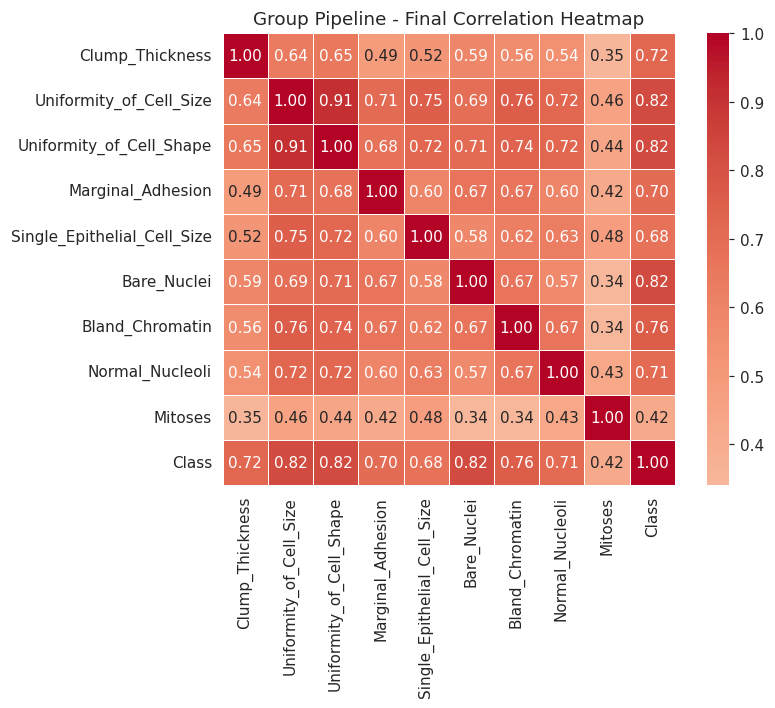

In [ ]:
corr_with_target = df[FEATURE_COLS + ['Class']].corr(numeric_only=True)['Class'].drop('Class').sort_values(ascending=False)
print("Step 5 complete - correlation with target (retained, none dropped):")
print(corr_with_target.round(3))

plt.figure(figsize=(8, 6.5))
sns.heatmap(df[FEATURE_COLS + ['Class']].corr(numeric_only=True).round(2), annot=True,
            cmap='coolwarm', center=0, square=True, linewidths=0.5, fmt='.2f')
plt.title('Group Pipeline - Final Correlation Heatmap')
plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/pipeline_correlation_heatmap.png', bbox_inches='tight')
plt.show()

## Step 6 - Dimensionality Reduction (PCA, Exploratory)
*(IT25102047)* Visualize class separability in 2D; confirm original 9 features are kept for modelling since 95% variance still needs 7 components.

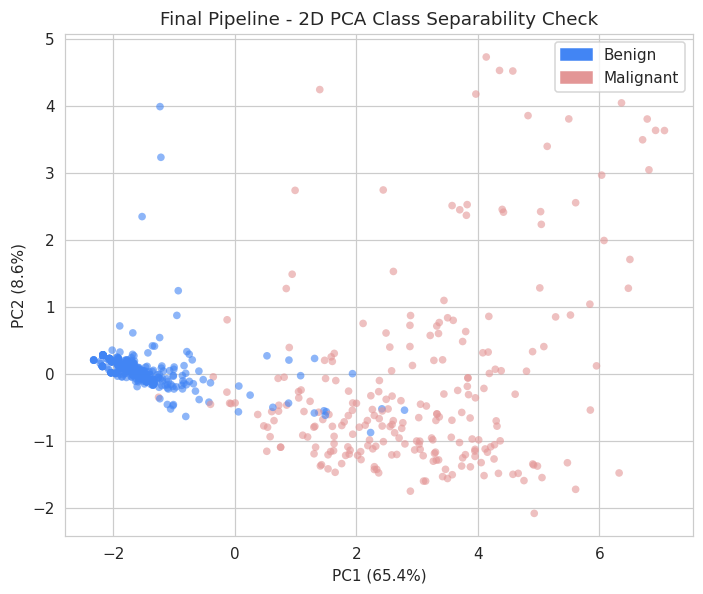

Step 6 complete - PCA used for visualization only; all 9 original features retained for modelling.


In [ ]:
X_scaled = df_scaled_features.values
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)

plt.figure(figsize=(6.5, 5.5))
colors = df['Class'].map({0: '#4285F4', 1: '#E39696'})
plt.scatter(pcs[:, 0], pcs[:, 1], c=colors, alpha=0.6, s=25, edgecolor='none')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Final Pipeline - 2D PCA Class Separability Check')
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='#4285F4', label='Benign'), Patch(color='#E39696', label='Malignant')])
plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/pipeline_pca_scatter.png', bbox_inches='tight')
plt.show()

print("Step 6 complete - PCA used for visualization only; all 9 original features retained for modelling.")

## Final Output
Save the fully processed dataset - original 9 features (outliers retained, missing values imputed), their standardized counterparts, and the binary-encoded target - ready for Step 3 (Model Design & Implementation).

In [ ]:
output_path = f'{OUT_DIR}/processed_breast_cancer.csv'
df_final.to_csv(output_path, index=False)

log_path = f'{LOG_DIR}/pipeline_log.txt'
with open(log_path, 'w') as f:
    f.write("ClearCell Group Preprocessing Pipeline - Execution Log\n")
    f.write("="*55 + "\n")
    f.write(f"Raw dataset shape       : {(699, 11)}\n")
    f.write(f"Missing values imputed  : {n_missing} (Bare_Nuclei, median={median_bn})\n")
    f.write(f"Target encoding         : 2->0 (Benign), 4->1 (Malignant)\n")
    f.write(f"Outliers flagged        : {any_outlier.sum()} rows ({pct_malignant_flagged:.1f}% malignant) - none removed\n")
    f.write(f"Scaling applied         : StandardScaler on all 9 features\n")
    f.write(f"Features retained       : 9 / 9 (all positively correlated with target)\n")
    f.write(f"PCA (exploratory)       : PC1+PC2 = {pca.explained_variance_ratio_.sum()*100:.1f}% variance\n")
    f.write(f"Final processed shape   : {df_final.shape}\n")
    f.write(f"Output file             : {output_path}\n")

print(f"Final processed dataset saved to: {output_path}")
print(f"Pipeline log saved to: {log_path}")
print("\nFinal dataset preview:")
df_final.head()

Final processed dataset saved to: results/outputs/processed_breast_cancer.csv
Pipeline log saved to: results/logs/pipeline_log.txt

Final dataset preview:


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


## Pipeline Summary
| Step | Technique | Result |
|---|---|---|
| 1 | Missing data handling | 16 values imputed (median) |
| 2 | Categorical encoding | Class → binary 0/1 |
| 3 | Outlier analysis | 195 flagged, 0 removed (signal, not error) |
| 4 | Feature scaling | 9 standardized columns added |
| 5 | Feature selection | 9/9 features retained, redundancy flagged |
| 6 | Dimensionality reduction | PCA used for visualization; 9 features kept for modelling |

**Output:** **results/outputs/processed_breast_cancer.csv** - 699 rows, ready for Step 3 model training.